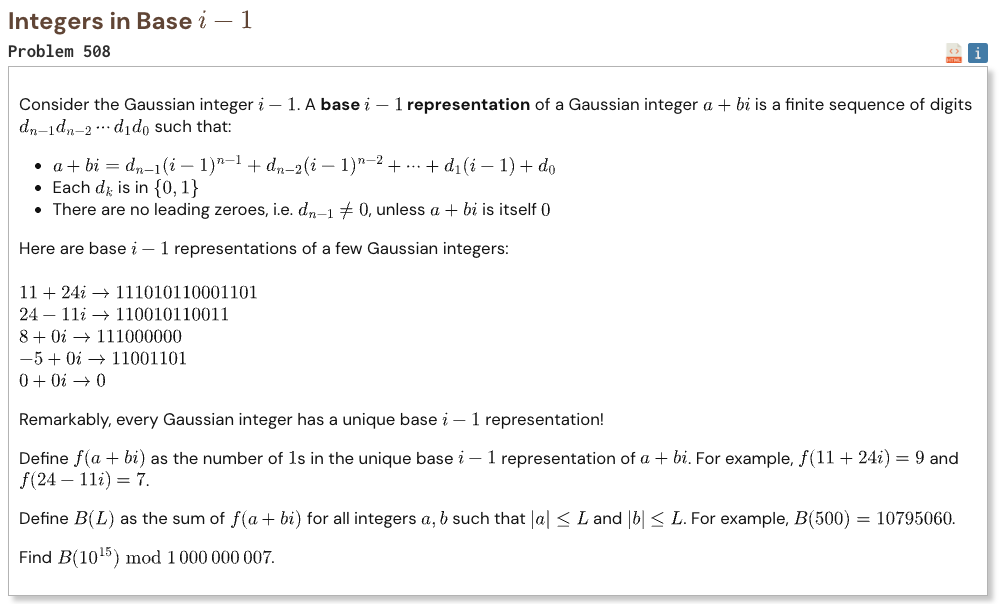

## Initial approach

 - repeatedly divide each Gaussian integer by the base and record whether the next digit is 0 or 1
- the next digit depends only on the parity of the real and imaginary parts
- after removing that digit, the remaining Gaussian integer is transformed into a smaller one
- apply the same transformation to whole rectangular regions instead of individual points
- the transformed region alternates between rectangles and rotated diamond shaped regions
- recursively sum the number of 1 digits over these regions
- switch to direct enumeration only when a region becomes very small
- use memoization so repeated subregions are calculated only once

In [1]:
%%time

from functools import lru_cache

MOD = 1_000_000_007
L = 10**15
BRUTE_LIMIT = 4000

def ceil_div(a, b):
    return -(-a // b)

def f(a, b):
    result = 0

    while a != 0 or b != 0:
        digit = (a ^ b) & 1

        if digit:
            a -= 1
            result += 1

        a, b = (b - a) // 2, -(a + b) // 2

    return result

def count_parity(low, high, parity):
    if low > high:
        return 0

    first = low if (low & 1) == parity else low + 1

    if first > high:
        return 0

    return (high - first) // 2 + 1

def count_rect(x0, x1, y0, y1):
    if x0 > x1 or y0 > y1:
        return 0

    return (x1 - x0 + 1) * (y1 - y0 + 1)

def count_diamond(u0, u1, v0, v1):
    if u0 > u1 or v0 > v1:
        return 0

    even_u = count_parity(u0, u1, 0)
    odd_u = u1 - u0 + 1 - even_u

    even_v = count_parity(v0, v1, 0)
    odd_v = v1 - v0 + 1 - even_v

    return even_u * even_v + odd_u * odd_v

def brute_rect(x0, x1, y0, y1):
    result = 0

    for a in range(x0, x1 + 1):
        for b in range(y0, y1 + 1):
            result += f(a, b)

    return result % MOD

def brute_diamond(u0, u1, v0, v1):
    result = 0

    for u in range(u0, u1 + 1):
        parity = u & 1
        start = v0 if (v0 & 1) == parity else v0 + 1

        for v in range(start, v1 + 1, 2):
            a = (u + v) // 2
            b = (u - v) // 2
            result += f(a, b)

    return result % MOD

@lru_cache(None)
def sum_rect(x0, x1, y0, y1):
    if x0 > x1 or y0 > y1:
        return 0

    size = count_rect(x0, x1, y0, y1)

    if size <= BRUTE_LIMIT:
        return brute_rect(x0, x1, y0, y1)

    d0 = (
        -x1,
        -x0,
        y0,
        y1
    )

    d1 = (
        -x1 + 1,
        -x0 + 1,
        y0,
        y1
    )

    return (
        sum_diamond(*d0)
        + sum_diamond(*d1)
        + count_diamond(*d1)
    ) % MOD

@lru_cache(None)
def sum_diamond(u0, u1, v0, v1):
    if u0 > u1 or v0 > v1:
        return 0

    size = count_diamond(u0, u1, v0, v1)

    if size <= BRUTE_LIMIT:
        return brute_diamond(u0, u1, v0, v1)

    r0 = (
        ceil_div(-v1, 2),
        (-v0) // 2,
        ceil_div(-u1, 2),
        (-u0) // 2
    )

    r1 = (
        ceil_div(1 - v1, 2),
        (1 - v0) // 2,
        ceil_div(1 - u1, 2),
        (1 - u0) // 2
    )

    return (
        sum_rect(*r0)
        + sum_rect(*r1)
        + count_rect(*r1)
    ) % MOD

result = sum_rect(-L, L, -L, L) % MOD

print("Result:", result)

Result: 891874596
CPU times: user 54.3 ms, sys: 1.64 ms, total: 56 ms
Wall time: 56.3 ms
